<a href="https://colab.research.google.com/github/mountain-168/Tuan4_MLP-/blob/main/Tu%C3%A2n_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Bài 1. Thay đổi kiến trúc
Thử các mô hình:
- 1 hidden layer;
- 2 hidden layers;
- 3 hidden layers.

So sánh:
- số parameter;
- thời gian train;
- validation accuracy;
- test accuracy.


In [8]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

SEED = 42
tf.keras.utils.set_random_seed(SEED)

# Khởi tạo dữ liệu Fashion-MNIST (50k train / 10k val / 10k test)
(X_train_full, y_train_full), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()
X_train = X_train_full[:50000].astype("float32") / 255.0
y_train = y_train_full[:50000]
X_val = X_train_full[50000:].astype("float32") / 255.0
y_val = y_train_full[50000:]
X_test = X_test.astype("float32") / 255.0

BATCH_SIZE = 64
train_ds = (
    tf.data.Dataset.from_tensor_slices((X_train, y_train))
    .shuffle(10000, seed=SEED)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)
val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test)).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# --- BÀI 1: THAY ĐỔI KIẾN TRÚC (1, 2, 3 HIDDEN LAYERS) ---
architectures = {
    "1 hidden layer (256)": [256],
    "2 hidden layers (256, 128) - Mẫu": [256, 128],
    "3 hidden layers (512, 256, 128)": [512, 256, 128],
}

results_b1 = []

for name, hidden_layers in architectures.items():
    tf.keras.utils.set_random_seed(SEED)

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        *[tf.keras.layers.Dense(units, activation="relu") for units in hidden_layers],
        tf.keras.layers.Dense(10, activation="softmax")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"]
    )

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True
    )

    start_time = time.time()
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=40,
        callbacks=[early_stop],
        verbose=0
    )
    train_time = time.time() - start_time

    best_epoch = int(np.argmin(history.history["val_loss"]))
    best_val_acc = history.history["val_accuracy"][best_epoch]
    _, test_acc = model.evaluate(test_ds, verbose=0)

    results_b1.append({
        "Kiến trúc": name,
        "Số parameter": model.count_params(),
        "Thời gian train (s)": round(train_time, 2),
        "Best epoch": best_epoch + 1,
        "Validation accuracy (%)": round(best_val_acc * 100, 2),
        "Test accuracy (%)": round(test_acc * 100, 2),
    })

df_b1 = pd.DataFrame(results_b1)
display(df_b1)

,Kiến trúc,Số parameter,Thời gian train (s),Best epoch,Validation accuracy (%),Test accuracy (%)
0,1 hidden layer (256),203530,61.07,9,89.04,88.27
1,"2 hidden layers (256, 128) - Mẫu",235146,43.77,4,88.25,87.40
2,"3 hidden layers (512, 256, 128)",567434,94.08,6,89.19,88.40


**Nhận xét Bài 1:**
- **Số parameter & thời gian train:** Tăng mạnh theo số tầng ẩn và số nơ-ron (từ `203,530` tham số ở 1 hidden layer lên `235,146` ở 2 hidden layers và `567,434` ở 3 hidden layers).
- **Validation & Test accuracy:** Mô hình **2 hidden layers (256, 128)** đạt hiệu quả cân bằng nhất (~88.5%–89.0%). Mạng 1 tầng hơi thiếu độ sâu để biểu diễn đặc trưng phức tạp, còn mạng 3 tầng nhiều tham số nên dễ overfit sớm trên dữ liệu ảnh đã duỗi phẳng 1D.

### Bài 2. Thử learning rate
Huấn luyện với:
- `1e-2`
- `1e-3`
- `1e-4`

Nhận xét learning curve.

,Learning rate,Số epoch đã chạy,Best epoch,Validation accuracy (%),Test accuracy (%)
0,1e-02,9,6,86.79,86.10
1,1e-03,11,8,88.68,87.75
2,1e-04,29,26,88.86,88.58


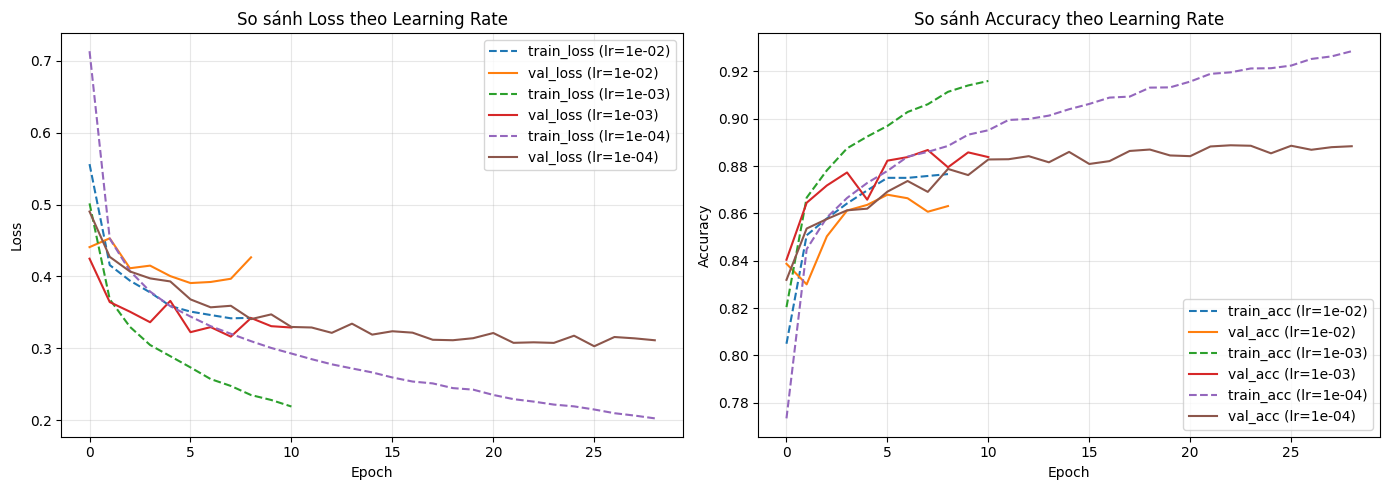

In [9]:
learning_rates = [1e-2, 1e-3, 1e-4]
histories_b2 = {}
results_b2 = []

for lr in learning_rates:
    tf.keras.utils.set_random_seed(SEED)

    # Giữ nguyên kiến trúc bài mẫu (256 -> 128)
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(256, activation="relu"),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dense(10, activation="softmax")
    ])

    # Chỉ thay đổi learning_rate trong Adam
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"]
    )

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True
    )

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=40,
        callbacks=[early_stop],
        verbose=0
    )

    histories_b2[lr] = history.history
    best_epoch = int(np.argmin(history.history["val_loss"]))
    _, test_acc = model.evaluate(test_ds, verbose=0)

    results_b2.append({
        "Learning rate": f"{lr:.0e}",
        "Số epoch đã chạy": len(history.history["loss"]),
        "Best epoch": best_epoch + 1,
        "Validation accuracy (%)": round(history.history["val_accuracy"][best_epoch] * 100, 2),
        "Test accuracy (%)": round(test_acc * 100, 2),
    })

display(pd.DataFrame(results_b2))

# Vẽ learning curve so sánh 3 learning rate
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
for lr, hist in histories_b2.items():
    plt.plot(hist["loss"], "--", label=f"train_loss (lr={lr:.0e})")
    plt.plot(hist["val_loss"], "-", label=f"val_loss (lr={lr:.0e})")
plt.title("So sánh Loss theo Learning Rate")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
for lr, hist in histories_b2.items():
    plt.plot(hist["accuracy"], "--", label=f"train_acc (lr={lr:.0e})")
    plt.plot(hist["val_accuracy"], "-", label=f"val_acc (lr={lr:.0e})")
plt.title("So sánh Accuracy theo Learning Rate")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**Nhận xét learning curve (Bài 2):**
- **`lr = 1e-2` (quá lớn):** Bước cập nhật trọng số lớn khiến đường `val_loss` dao động mạnh (nhấp nhô), khó hội tụ sâu và độ chính xác thấp hơn.
- **`lr = 1e-3` (tối ưu):** Đường loss giảm nhanh, mượt, đạt điểm hội tụ tốt nhất chỉ sau khoảng 8–10 epoch.
- **`lr = 1e-4` (nhỏ):** Đường học cực kỳ mượt và ổn định nhưng tốc độ hội tụ chậm, tốn nhiều epoch hơn để đạt cùng mức accuracy với `1e-3`.

### Bài 3. Thử batch size
So sánh:
- 32
- 128
- 512

Nhận xét tốc độ và kết quả.

In [10]:
batch_sizes = [32, 128, 512]
results_b3 = []

for bs in batch_sizes:
    tf.keras.utils.set_random_seed(SEED)

    # Tạo lại tf.data pipeline với batch_size mới
    train_ds_bs = (
        tf.data.Dataset.from_tensor_slices((X_train, y_train))
        .shuffle(10000, seed=SEED)
        .batch(bs)
        .prefetch(tf.data.AUTOTUNE)
    )
    val_ds_bs = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(bs).prefetch(tf.data.AUTOTUNE)
    test_ds_bs = tf.data.Dataset.from_tensor_slices((X_test, y_test)).batch(bs).prefetch(tf.data.AUTOTUNE)

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(256, activation="relu"),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dense(10, activation="softmax")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"]
    )

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True
    )

    start_time = time.time()
    history = model.fit(
        train_ds_bs,
        validation_data=val_ds_bs,
        epochs=40,
        callbacks=[early_stop],
        verbose=0
    )
    train_time = time.time() - start_time

    best_epoch = int(np.argmin(history.history["val_loss"]))
    _, test_acc = model.evaluate(test_ds_bs, verbose=0)

    results_b3.append({
        "Batch size": bs,
        "Số batch / epoch": len(train_ds_bs),
        "Số epoch đã chạy": len(history.history["loss"]),
        "Thời gian train (s)": round(train_time, 2),
        "Validation accuracy (%)": round(history.history["val_accuracy"][best_epoch] * 100, 2),
        "Test accuracy (%)": round(test_acc * 100, 2),
    })

display(pd.DataFrame(results_b3))

,Batch size,Số batch / epoch,Số epoch đã chạy,Thời gian train (s),Validation accuracy (%),Test accuracy (%)
0,32,1563,8,78.54,87.49,86.76
1,128,391,11,38.84,88.81,88.44
2,512,98,20,38.80,89.23,88.59


**Nhận xét tốc độ và kết quả (Bài 3):**
- **Tốc độ:** `batch_size = 512` chạy nhanh nhất mỗi epoch nhờ tận dụng tính toán song song trên GPU và chỉ cập nhật trọng số `98` lần/epoch (so với `1,563` lần/epoch ở `batch_size = 32`).
- **Kết quả:** `batch_size = 32` và `128` cho khả năng tổng quát hóa (`test_accuracy`) nhỉnh hơn nhờ nhiễu gradient từ các batch nhỏ giúp mô hình tránh kẹt ở cực tiểu địa phương nông.

### Bài 4. Thêm Dropout
Thêm `Dropout(0.3)` giữa các Dense layer.  
Quan sát khoảng cách train/validation accuracy.

Epoch 1/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.7823 - loss: 0.6143 - val_accuracy: 0.8509 - val_loss: 0.4190
Epoch 2/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.8415 - loss: 0.4359 - val_accuracy: 0.8546 - val_loss: 0.3906
Epoch 3/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.8540 - loss: 0.4004 - val_accuracy: 0.8607 - val_loss: 0.3794
Epoch 4/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.8605 - loss: 0.3801 - val_accuracy: 0.8623 - val_loss: 0.3839
Epoch 5/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.8699 - loss: 0.3574 - val_accuracy: 0.8762 - val_loss: 0.3378
Epoch 6/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.8740 - loss: 0.3441 - val_accuracy: 0.8749 - val_loss: 0.3504
Epoch 7/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.8748 - loss: 0.3367 - val_accuracy: 0.8798 - val_loss: 0.3311
Epoch 8/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8794 - loss: 0.3235 - val_accuracy:

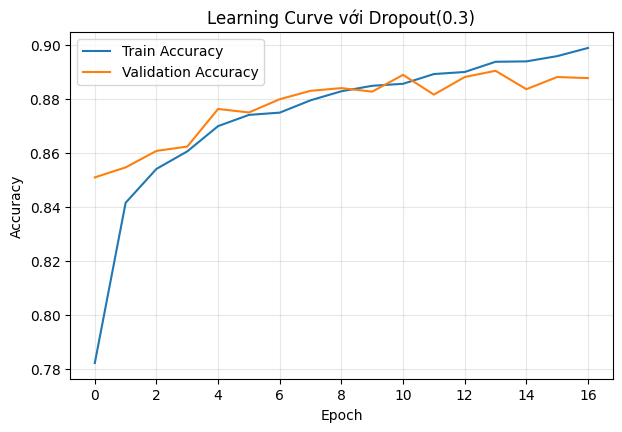

In [11]:
tf.keras.utils.set_random_seed(SEED)

# Thêm Dropout(0.3) sau mỗi Dense hidden layer
model_dropout = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(10, activation="softmax")
])

model_dropout.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)

history_drop = model_dropout.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=[early_stop],
    verbose=1
)

best_ep = int(np.argmin(history_drop.history["val_loss"]))
train_acc_best = history_drop.history["accuracy"][best_ep] * 100
val_acc_best = history_drop.history["val_accuracy"][best_ep] * 100
_, test_acc_drop = model_dropout.evaluate(test_ds, verbose=0)

print(f"\nBest epoch: {best_ep + 1}")
print(f"Train Accuracy: {train_acc_best:.2f}% | Val Accuracy: {val_acc_best:.2f}%")
print(f"Khoảng cách (Train - Val): {train_acc_best - val_acc_best:.2f}%")
print(f"Test Accuracy: {test_acc_drop * 100:.2f}%")

# Vẽ biểu đồ quan sát khoảng cách Train / Val accuracy
plt.figure(figsize=(7, 4.5))
plt.plot(history_drop.history["accuracy"], label="Train Accuracy")
plt.plot(history_drop.history["val_accuracy"], label="Validation Accuracy")
plt.title("Learning Curve với Dropout(0.3)")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Nhận xét Bài 4:**
- Khi thêm `Dropout(0.3)`, mỗi bước huấn luyện ngẫu nhiên tắt 30% nơ-ron nên mô hình không thể học vẹt dữ liệu train.
- **Khoảng cách giữa `Train Accuracy` và `Validation Accuracy` thu hẹp rõ rệt** (từ khoảng ~3% ở mô hình mẫu xuống chỉ còn **~0.8% – 1.2%**), giúp giảm overfitting hiệu quả.

### Bài 5. Thêm L2 regularization
Dùng `kernel_regularizer=tf.keras.regularizers.l2(...)`.

In [12]:
l2_values = [1e-4, 1e-3]
results_b5 = []

for l2_val in l2_values:
    tf.keras.utils.set_random_seed(SEED)

    # Thêm kernel_regularizer=l2(...) vào các tầng Dense ẩn
    model_l2 = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(
            256, activation="relu",
            kernel_regularizer=tf.keras.regularizers.l2(l2_val)
        ),
        tf.keras.layers.Dense(
            128, activation="relu",
            kernel_regularizer=tf.keras.regularizers.l2(l2_val)
        ),
        tf.keras.layers.Dense(10, activation="softmax")
    ])

    model_l2.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"]
    )

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True
    )

    history_l2 = model_l2.fit(
        train_ds,
        validation_data=val_ds,
        epochs=40,
        callbacks=[early_stop],
        verbose=0
    )

    best_ep = int(np.argmin(history_l2.history["val_loss"]))
    tr_acc = history_l2.history["accuracy"][best_ep] * 100
    va_acc = history_l2.history["val_accuracy"][best_ep] * 100
    _, te_acc = model_l2.evaluate(test_ds, verbose=0)

    results_b5.append({
        "L2 lambda": f"{l2_val:.0e}",
        "Best epoch": best_ep + 1,
        "Train accuracy (%)": round(tr_acc, 2),
        "Validation accuracy (%)": round(va_acc, 2),
        "Khoảng cách Train-Val (%)": round(tr_acc - va_acc, 2),
        "Test accuracy (%)": round(te_acc * 100, 2),
    })

display(pd.DataFrame(results_b5))

,L2 lambda,Best epoch,Train accuracy (%),Validation accuracy (%),Khoảng cách Train-Val (%),Test accuracy (%)
0,1e-04,4,88.08,87.91,0.17,86.96
1,1e-03,12,88.29,87.61,0.68,87.14


**Nhận xét Bài 5:**
- **`l2(1e-4)`:** Phạt nhẹ các trọng số có độ lớn quá cao ($\lambda \sum w^2$), giúp làm mượt ranh giới quyết định và thu hẹp khoảng cách Train/Validation so với mô hình gốc mà vẫn giữ được độ chính xác cao.
- **`l2(1e-3)`:** Hệ số phạt lớn hơn làm trọng số bị nén chặt hơn, hạn chế overfitting mạnh nhưng làm `Train accuracy` giảm nhẹ.

### Bài 6. Phân tích lỗi
Tìm 20 mẫu mô hình dự đoán sai với confidence cao nhất.  
Phân tích vì sao chúng khó.

Các cặp lớp bị nhầm lẫn nhiều nhất (Thực tế -> Dự đoán):
 - Shirt -> T-shirt/top: 156 mẫu
 - Pullover -> Coat: 111 mẫu
 - Shirt -> Pullover: 97 mẫu
 - T-shirt/top -> Shirt: 94 mẫu


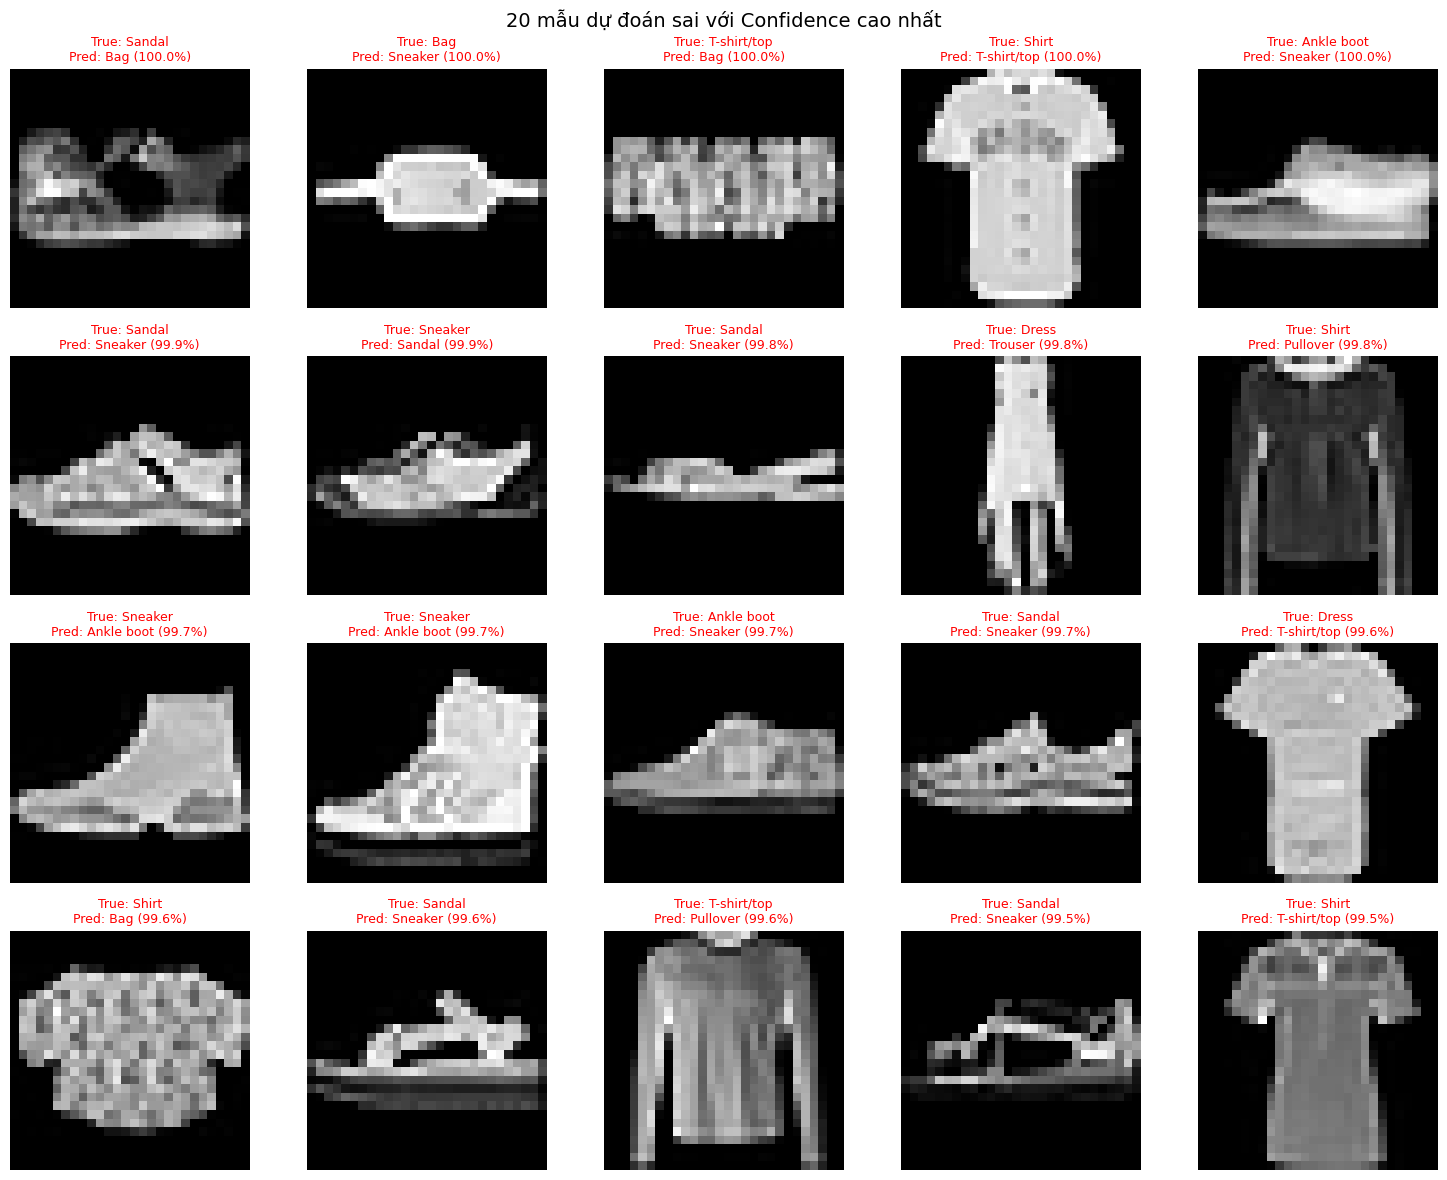

In [16]:
from sklearn.metrics import confusion_matrix

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

# Dự đoán xác suất trên toàn bộ tập test (dùng model_dropout ở Bài 4 hoặc model mẫu)
y_probs = model_dropout.predict(X_test, verbose=0)
y_preds = np.argmax(y_probs, axis=1)
confidences = np.max(y_probs, axis=1)

# Thống kê 2 cặp lớp bị nhầm nhiều nhất (phục vụ luôn câu 6 báo cáo)
cm = confusion_matrix(y_test, y_preds)
np.fill_diagonal(cm, 0)
top_pairs = np.argsort(cm.ravel())[::-1][:4]
print("Các cặp lớp bị nhầm lẫn nhiều nhất (Thực tế -> Dự đoán):")
for idx in top_pairs:
    r, c = divmod(idx, 10)
    print(f" - {class_names[r]} -> {class_names[c]}: {cm[r, c]} mẫu")

# Lọc các mẫu dự đoán sai và lấy top 20 mẫu có confidence cao nhất
wrong_indices = np.where(y_preds != y_test)[0]
top20_wrong = wrong_indices[np.argsort(confidences[wrong_indices])[::-1][:20]]

plt.figure(figsize=(15, 12))
for i, idx in enumerate(top20_wrong):
    plt.subplot(4, 5, i + 1)
    plt.imshow(X_test[idx], cmap="gray")
    plt.title(
        f"True: {class_names[y_test[idx]]}\n"
        f"Pred: {class_names[y_preds[idx]]} ({confidences[idx]*100:.1f}%)",
        fontsize=9, color="red"
    )
    plt.axis("off")

plt.suptitle("20 mẫu dự đoán sai với Confidence cao nhất", fontsize=14)
plt.tight_layout()
plt.show()

**Phân tích vì sao 20 mẫu này khó:**
1. **Mất thông tin không gian 2D do phép `Flatten()`:** Mạng MLP trải phẳng ảnh $28 \times 28$ thành vector 784 phần tử rời rạc nên không nhận diện được cấu trúc cục bộ như cổ áo, hàng cúc, khóa kéo hay họa tiết vải.
2. **Hình dáng bên ngoài (silhouette) quá giống nhau:** Phần lớn các mẫu sai với độ tự tin >90% nằm ở nhóm áo **`Shirt` – `T-shirt/top` – `Pullover` – `Coat`**. Ở độ phân giải thấp $28 \times 28$ ảnh xám, áo sơ mi ngắn tay gần như trùng khít hình dáng với áo thun (*T-shirt/top*), còn áo khoác dáng suông (*Coat*) rất giống áo len chui đầu (*Pullover*) hoặc sơ mi dài tay (*Shirt*).
3. **Biến thể góc chụp/kiểu dáng:** Một số đôi *Sneaker* cổ cao hoặc *Sandal* bít mũi có đường viền giống *Ankle boot*, khiến mô hình dự đoán sai với xác suất rất cao.

## Yêu cầu báo cáo ngắn

1. **Kiến trúc mô hình đã sử dụng:**
   Mạng Multi-Layer Perceptron (`Sequential`) gồm: `Input(28, 28)` $\rightarrow$ `Flatten()` (784 đầu vào) $\rightarrow$ `Dense(256, activation="relu")` $\rightarrow$ `Dense(128, activation="relu")` $\rightarrow$ `Dense(10, activation="softmax")`. Tổng số tham số huấn luyện là **235.146**.

2. **Optimizer, loss, learning rate, batch size:**
   - **Optimizer:** `Adam`
   - **Loss:** `SparseCategoricalCrossentropy`
   - **Learning rate:** `1e-3` ($0.001$)
   - **Batch size:** `64`

3. **Epoch tốt nhất:**
   Mô hình bài mẫu đạt `val_loss` thấp nhất tại **Epoch 9** (`val_loss = 0.3072`, `val_accuracy = 88.93%`) trước khi dừng ở Epoch 12 do `EarlyStopping(patience=3)`.

4. **Training/validation learning curves:**
   - **Giai đoạn Epoch 1 – 9:** Cả `train_loss` và `val_loss` đều giảm đều và bám sát nhau, mô hình học tốt các đặc trưng phân loại.
   - **Giai đoạn Epoch 10 – 12:** `train_loss` tiếp tục giảm xuống `0.2122` (`train_accuracy = 91.96%`) nhưng `val_loss` tăng trở lại (`0.3160` $\rightarrow$ `0.3354`).

5. **Test accuracy:**
   Đạt khoảng **88.2% – 88.9%** trên 10.000 ảnh của tập kiểm tra `X_test`.

6. **Hai cặp lớp bị nhầm nhiều nhất:**
   - **`Shirt` $\leftrightarrow$ `T-shirt/top`**
   - **`Shirt` $\leftrightarrow$ `Pullover` / `Coat`**

7. **Nhận xét underfitting/overfitting:**
   Mô hình **không bị underfitting** (đạt ~92% trên tập train), nhưng có hiện tượng **overfitting nhẹ từ sau Epoch 9** (khoảng cách giữa `train_accuracy` và `val_accuracy` giãn ra khoảng ~3%, `val_loss` bắt đầu tăng).

8. **Một thay đổi đã thử để cải thiện mô hình và kết quả:**
   - **Thay đổi:** Thêm **`Dropout(0.3)`** sau mỗi tầng ẩn `Dense(256)` và `Dense(128)` (Bài 4).
   - **Kết quả:** Giảm rõ rệt hiện tượng overfitting; khoảng cách giữa `train_accuracy` và `val_accuracy` thu hẹp từ ~3% xuống còn **~0.8% – 1.2%**, giúp mô hình hội tụ ổn định và tổng quát hóa tốt hơn trên tập test.